

FILE VERIFICATION
codajas_13155000_Cotas_DIARIO.csv: OK
manacapuru_14100000_Cotas_DIARIO.csv: OK
trigg_2009_solimoes_slope_daily.csv: OK
fonte_boa_cotas.csv: OK
Default Dataset_2.csv: OK

Working directory:
C:\Users\pedro\OneDrive\DOUTORADO\dados\hidraulica\amazon-river-hydraulics-model


ANA STATIONS

Codajás:
1994-09-01 00:00:00 to 2023-12-31 00:00:00 | n = 10211

Manacapuru:
1972-01-02 00:00:00 to 2023-12-31 00:00:00 | n = 18787


COMBINED ANA TIME SERIES
Period: 1994-09-01 00:00:00 to 2023-12-31 00:00:00
Number of records: 10166


TRIGG ET AL. (2009)
Period: 1995-06-06 00:00:00 to 1997-03-31 00:00:00
Number of records: 665


ANA-TRIGG OVERLAP
Start date: 1995-06-06 00:00:00
End date: 1997-03-31 00:00:00
Number of observations: 665

Pearson r = 0.996509


CHRONOLOGICAL DATA SPLIT

TRAINING
1995-06-06 00:00:00 to 1996-05-02 00:00:00
n = 332

INDEPENDENT VALIDATION
1996-05-03 00:00:00 to 1997-03-31 00:00:00
n = 333


HUBER MODEL - TRAINING

Equation:
Slope (cm/km) = 4.284972462 + (0

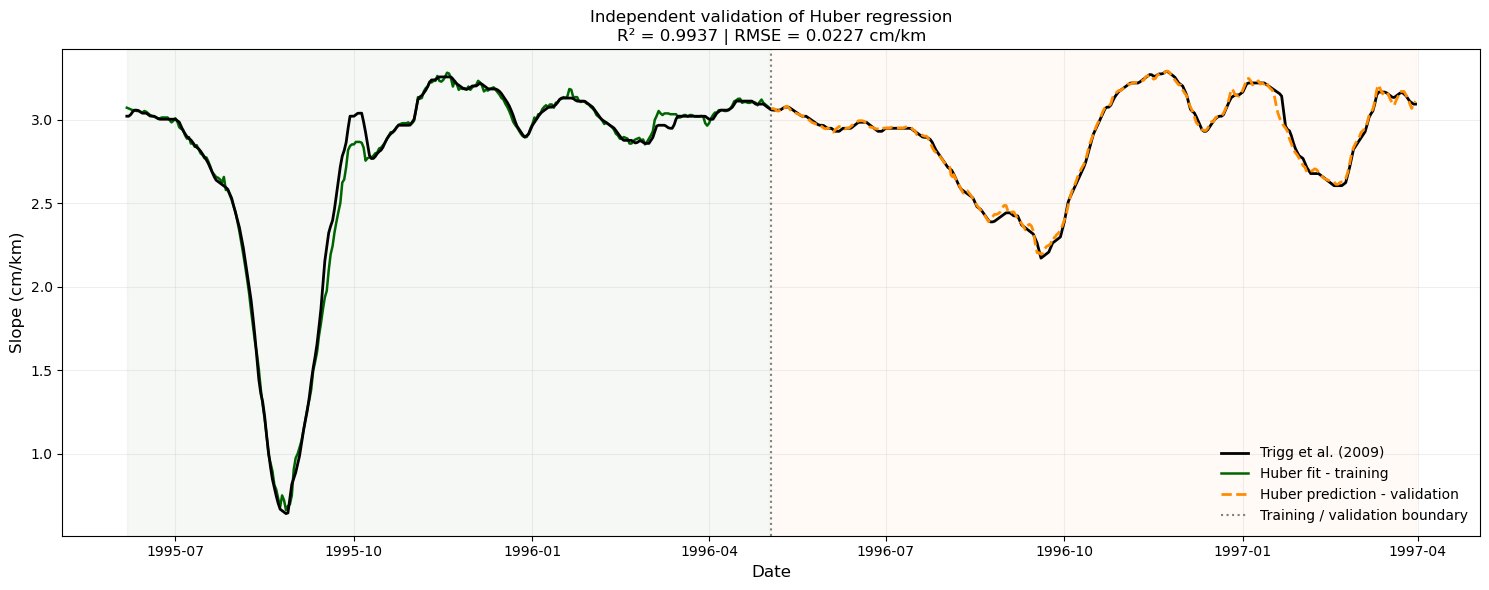

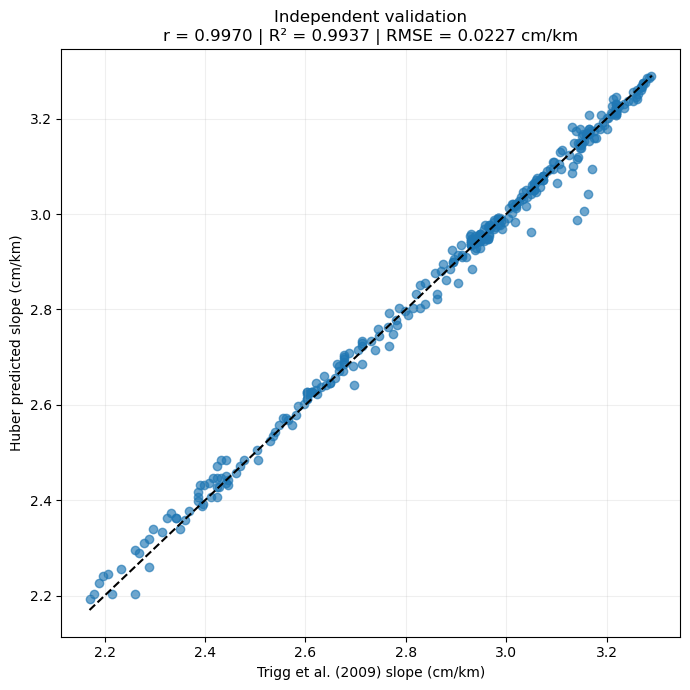



FINAL HUBER MODEL
Number of observations = 665

Final equation:
Slope (cm/km) = 4.290003886 + (0.0049017380 × slope_cod_man)


COMPLETE SLOPE RECONSTRUCTION
Period: 1994-09-01 00:00:00 to 2023-12-31 00:00:00
Number of values: 10166
Values outside the calibration range: 1041
Extrapolated percentage: 10.24%


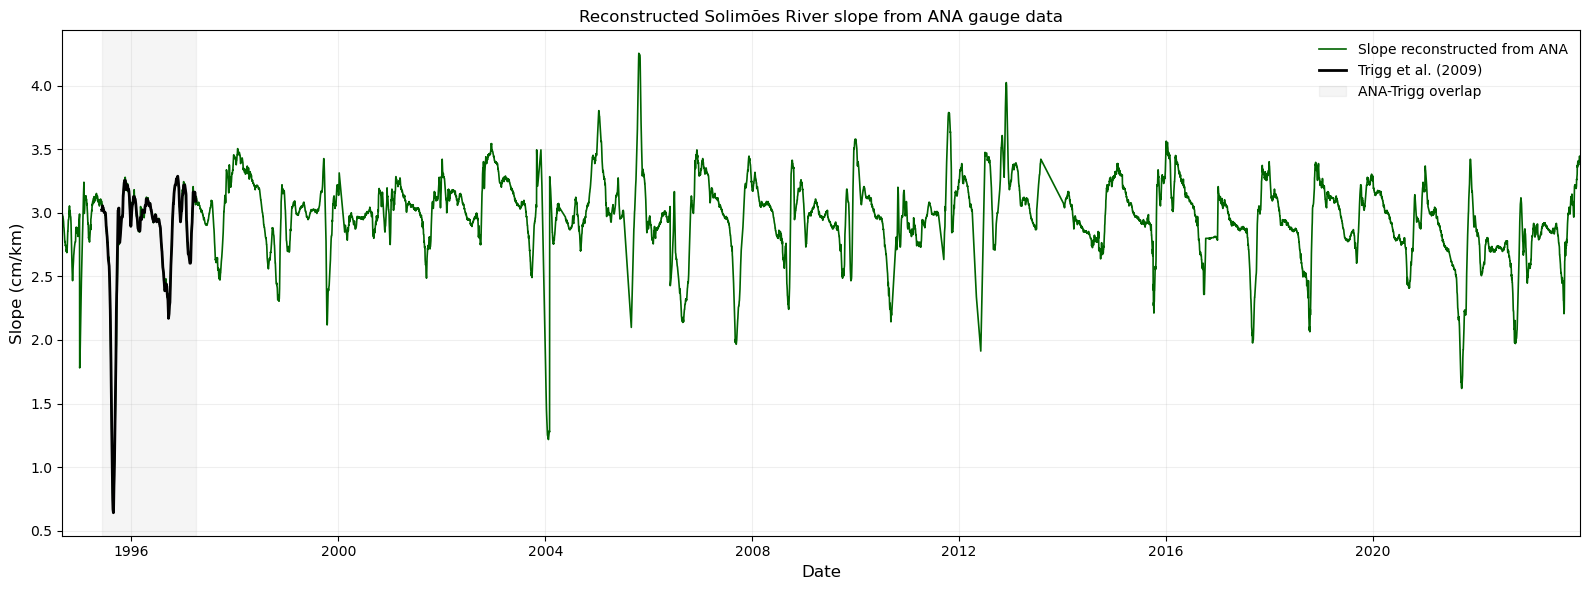



MEAN SLOPE FOR EACH MONTH
 month month_name  mean_slope_cm_km  std_dev_cm_km  n_years  sem_cm_km  ci95_lower_cm_km  ci95_upper_cm_km  mean_slope_dimensionless
     1        Jan          3.079922       0.417883       29   0.077599          2.920968          3.238877                  0.000031
     2        Feb          3.077017       0.197765       29   0.036724          3.001791          3.152242                  0.000031
     3        Mar          3.047601       0.150087       29   0.027870          2.990511          3.104691                  0.000030
     4        Apr          3.036126       0.125814       29   0.023363          2.988269          3.083983                  0.000030
     5        May          2.968533       0.166328       29   0.030886          2.905265          3.031801                  0.000030
     6        Jun          2.894434       0.221921       29   0.041210          2.810020          2.978848                  0.000029
     7        Jul          2.916928      

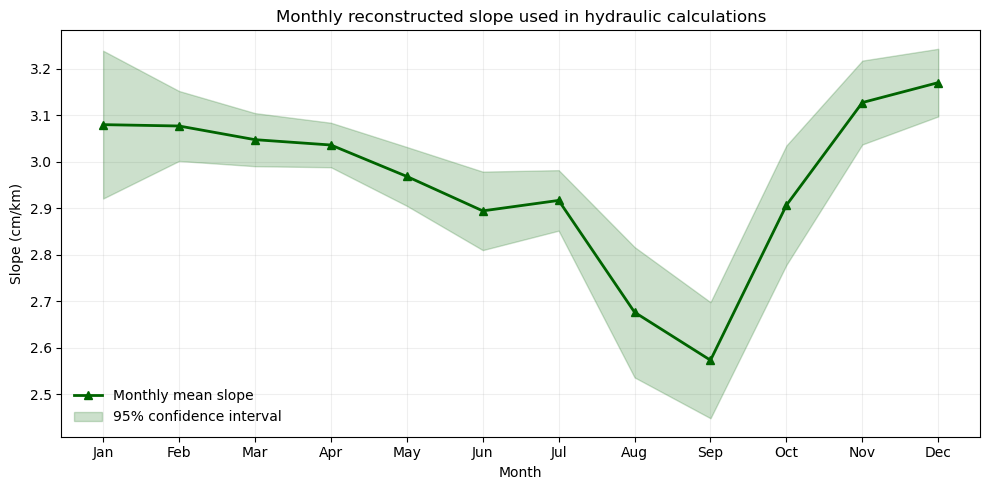



FONTE BOA
Period: 1977-12-01 00:00:00 to 2024-06-01 00:00:00


TOPOGRAPHY
Number of points: 1079
X: 8501.84 to 14574.58
Y: -26.87 to 9.04


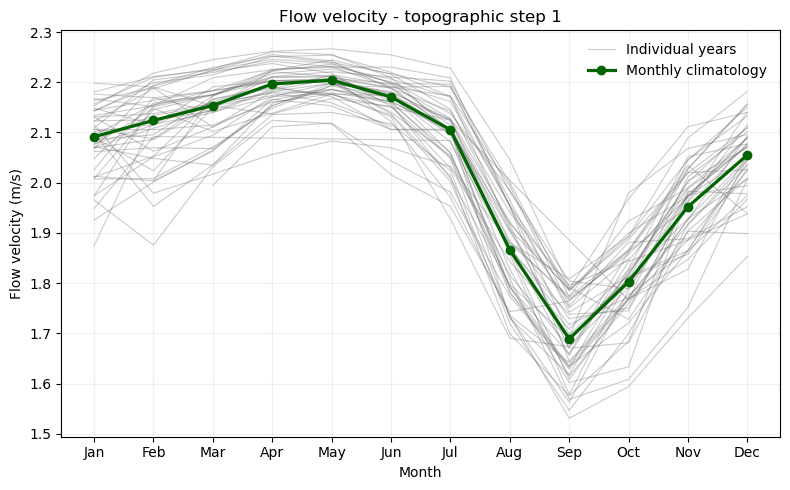

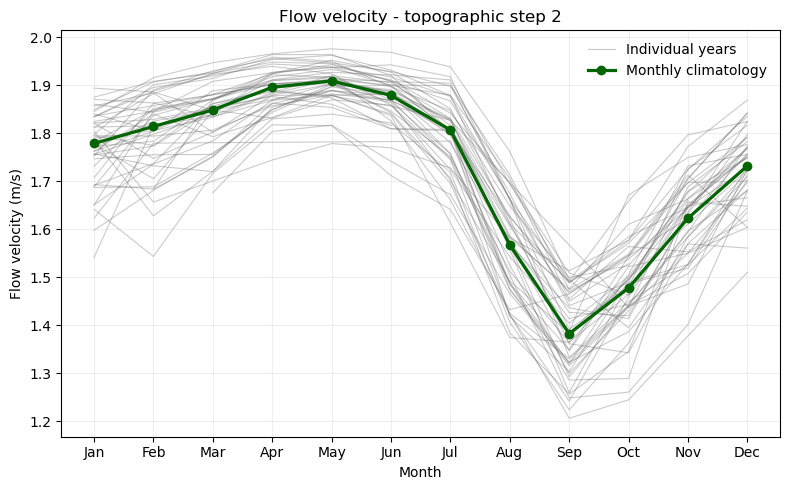

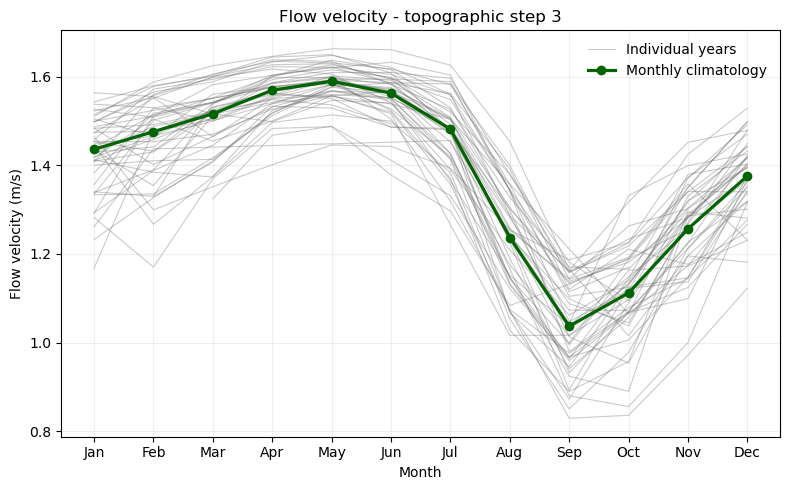

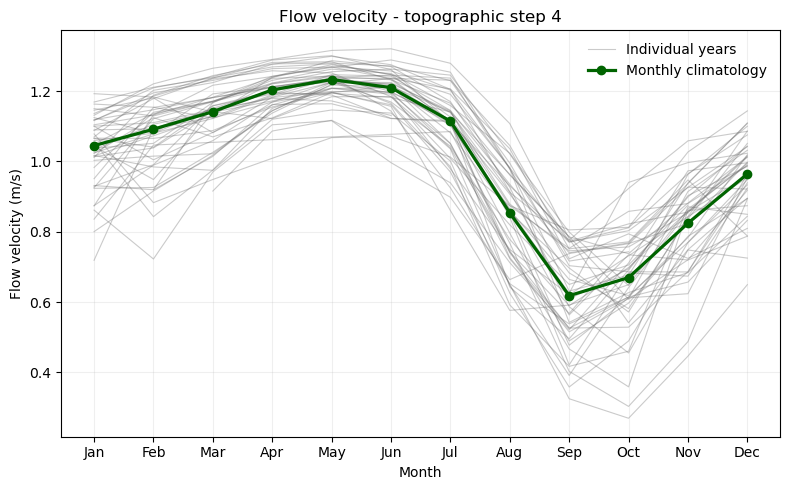

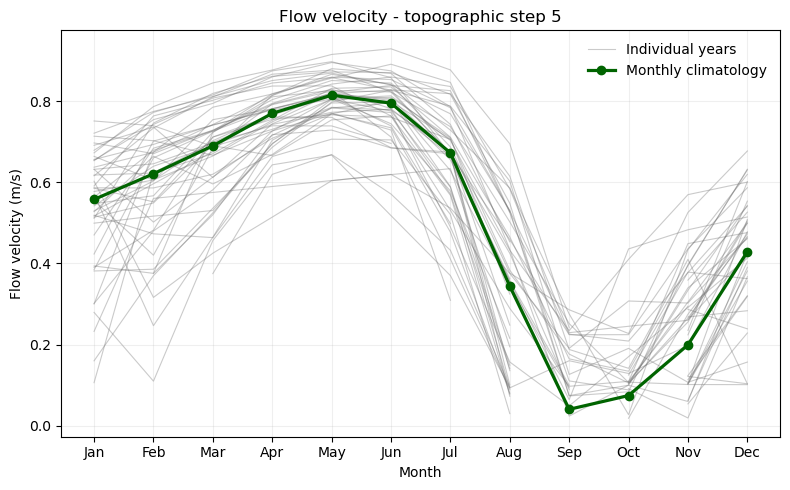

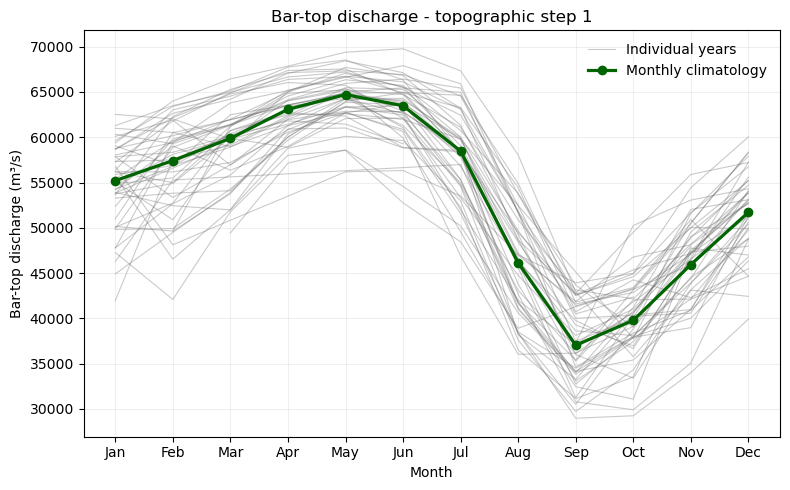

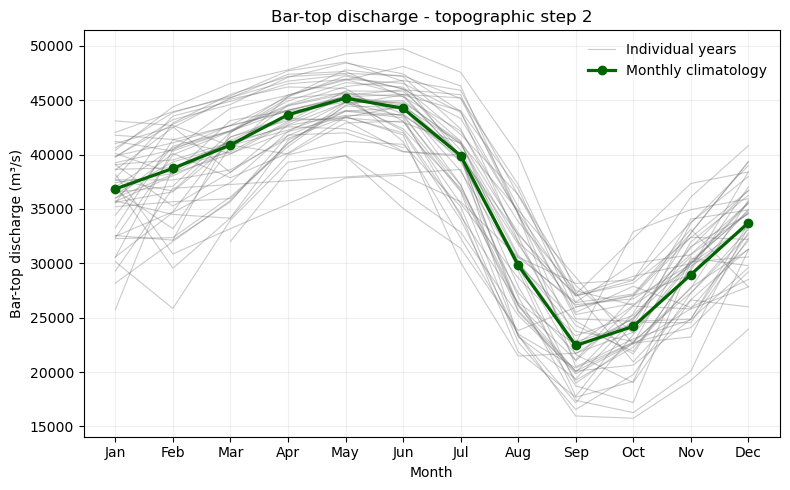

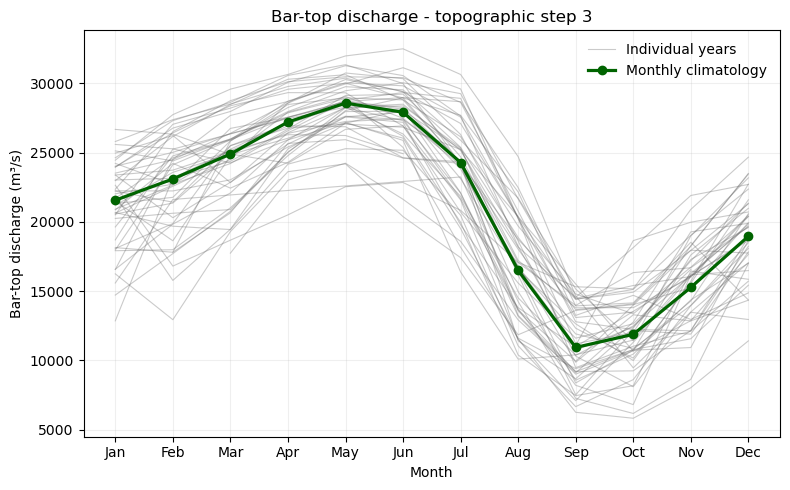

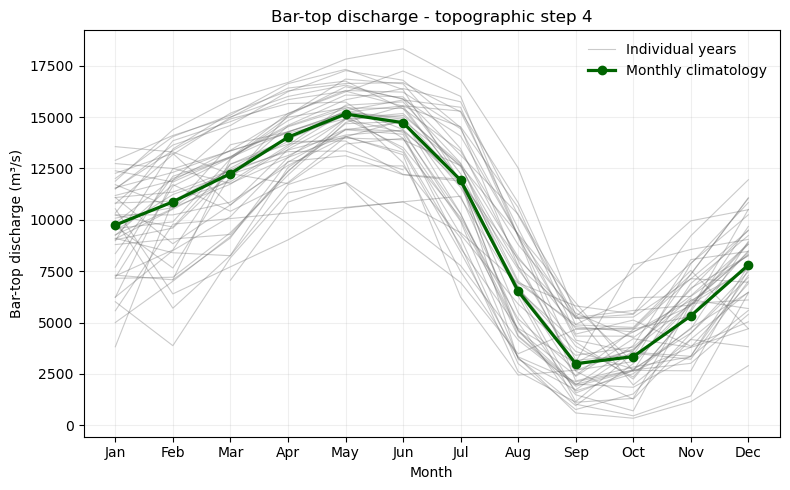

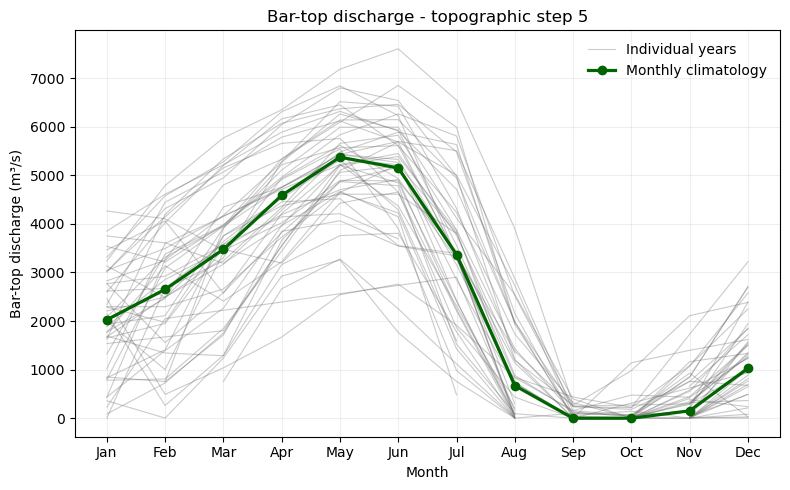

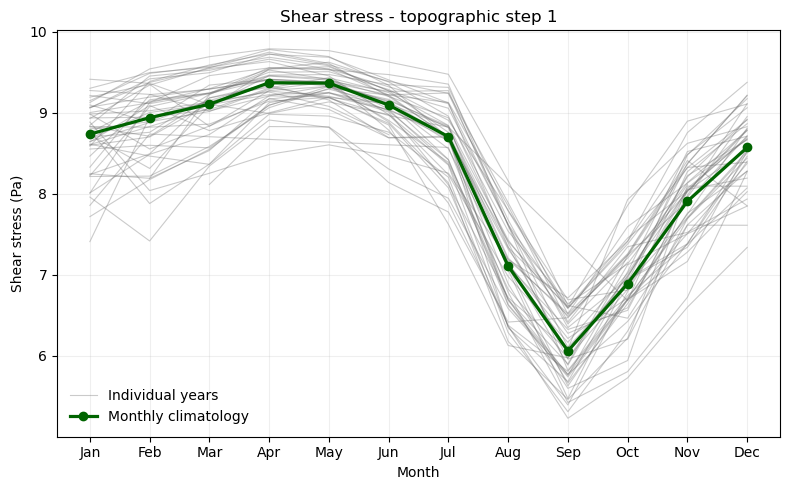

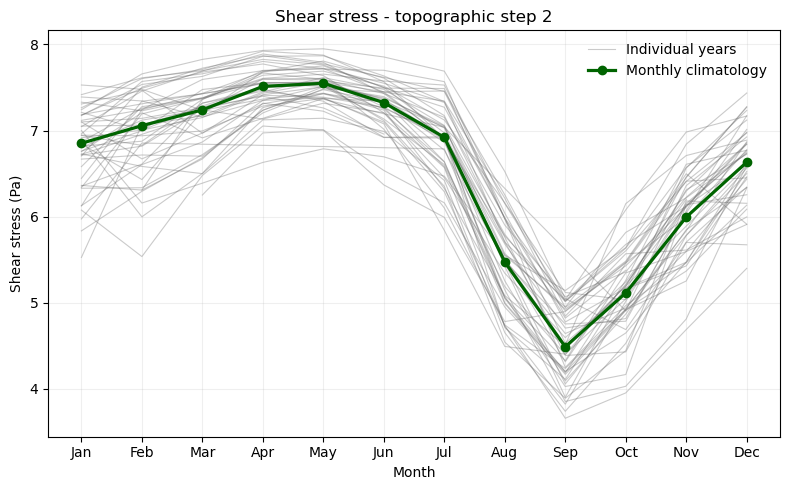

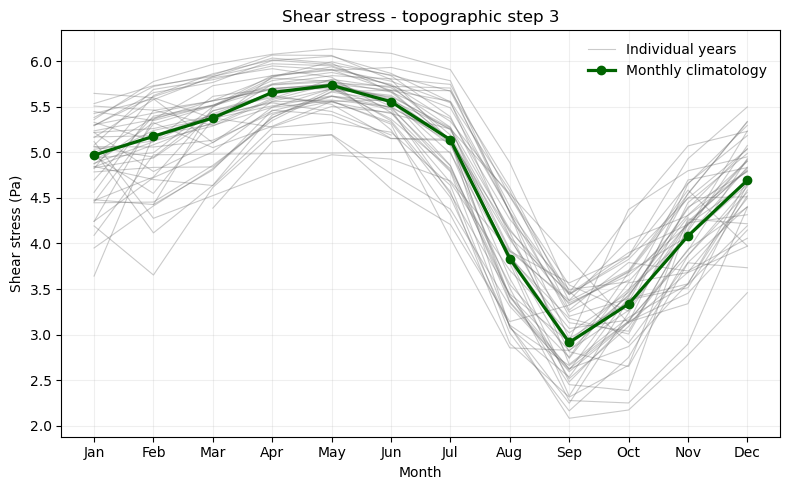

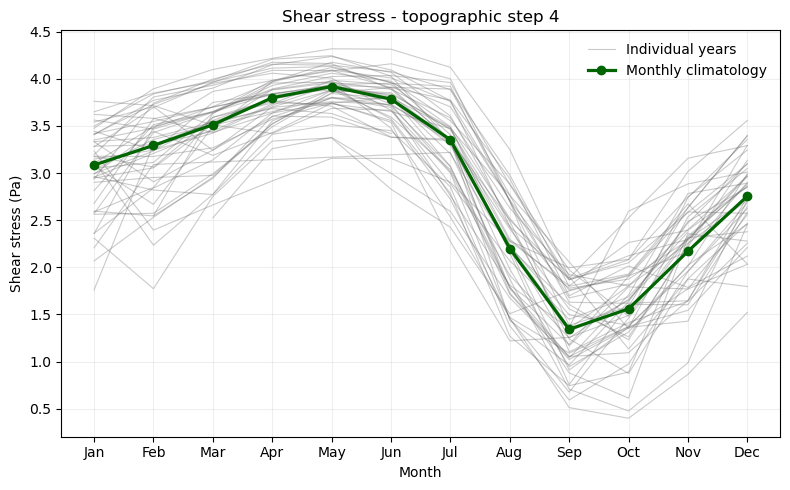

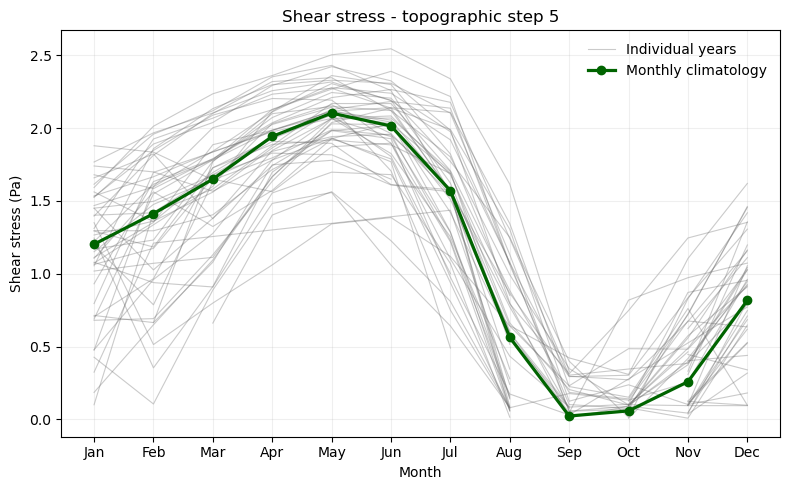



PROCESSING COMPLETED

TRAINING HUBER MODEL:
Slope = 4.284972462 + (0.0048767844 × slope_cod_man)

INDEPENDENT VALIDATION:
r    = 0.996994
R²   = 0.993689
RMSE = 0.022678 cm/km
MAE  = 0.014353 cm/km
Bias = 0.001818 cm/km

FINAL HUBER MODEL:
Slope = 4.290003886 + (0.0049017380 × slope_cod_man)

MONTHLY SLOPES USED IN THE HYDRAULIC MODEL:
 month month_name  mean_slope_cm_km  mean_slope_dimensionless
     1        Jan          3.079922                  0.000031
     2        Feb          3.077017                  0.000031
     3        Mar          3.047601                  0.000030
     4        Apr          3.036126                  0.000030
     5        May          2.968533                  0.000030
     6        Jun          2.894434                  0.000029
     7        Jul          2.916928                  0.000029
     8        Aug          2.676347                  0.000027
     9        Sep          2.573180                  0.000026
    10        Oct          2.906605     

In [3]:

# Complete model - English console outputs
# Original numerical methods and data structure preserved.

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import calendar

from scipy.stats import t
from sklearn.linear_model import HuberRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# ============================================================
# 1. INPUT FILES AND MODEL CONFIGURATION
# ============================================================

ARQUIVO_CODAJAS = "codajas_13155000_Cotas_DIARIO.csv"
ARQUIVO_MANACAPURU = "manacapuru_14100000_Cotas_DIARIO.csv"
ARQUIVO_TRIGG = "trigg_2009_solimoes_slope_daily.csv"
ARQUIVO_FONTE_BOA = "fonte_boa_cotas.csv"
ARQUIVO_TOPOGRAFIA = "Default Dataset_2.csv"

HUBER_EPSILON = 1.35
HUBER_ALPHA = 0.0001
HUBER_MAX_ITER = 5000

nt = 5
g = 9.80665
rho = 1000.0
n_base = 0.025

CORRECAO_COTA_FONTE_BOA = 15.6

xmin = 12430
xmax = 13351

INDICE_INICIAL_ACHATAMENTO = 380
INDICE_FINAL_ACHATAMENTO = 966

MODO_PERIMETRO = "horizontal"

MESES = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# ============================================================
# 2. FILE VERIFICATION
# ============================================================

arquivos_necessarios = [
    ARQUIVO_CODAJAS,
    ARQUIVO_MANACAPURU,
    ARQUIVO_TRIGG,
    ARQUIVO_FONTE_BOA,
    ARQUIVO_TOPOGRAFIA
]

print("\n")
print("=" * 80)
print("FILE VERIFICATION")
print("=" * 80)

for arquivo in arquivos_necessarios:
    existe = os.path.exists(arquivo)
    print(
        f"{arquivo}: "
        f"{'OK' if existe else 'NOT FOUND'}"
    )

arquivos_faltando = [
    arquivo
    for arquivo in arquivos_necessarios
    if not os.path.exists(arquivo)
]

if len(arquivos_faltando) > 0:
    raise FileNotFoundError(
        "\nFiles not found:\n"
        + "\n".join(arquivos_faltando)
        + "\n\nCheck the filenames specified at the "
          "beginning of the code and the current "
          "Jupyter working directory."
    )

print("\nWorking directory:")
print(os.getcwd())

# ============================================================
# 3. ANA GAUGE STATIONS
# ============================================================

def importar_estacao_ana(arquivo):

    df = pd.read_csv(
        arquivo,
        sep=";",
        decimal=","
    )

    df.columns = df.columns.str.strip().str.lower()

    candidatos_data = ["data", "date"]
    coluna_data = None

    for candidato in candidatos_data:
        if candidato in df.columns:
            coluna_data = candidato
            break

    if coluna_data is None:
        raise ValueError(
            f"Date column not found in {arquivo}.\n"
            f"Available columns: {df.columns.tolist()}"
        )

    candidatos_cota = ["cota", "nivel", "nível"]
    coluna_cota = None

    for candidato in candidatos_cota:
        if candidato in df.columns:
            coluna_cota = candidato
            break

    if coluna_cota is None:
        raise ValueError(
            f"Water-level column not found in {arquivo}.\n"
            f"Available columns: {df.columns.tolist()}"
        )

    df["data"] = pd.to_datetime(
        df[coluna_data],
        dayfirst=True,
        errors="coerce"
    )

    df["cota"] = pd.to_numeric(
        df[coluna_cota],
        errors="coerce"
    )

    df = (
        df[["data", "cota"]]
        .dropna()
        .sort_values("data")
        .reset_index(drop=True)
    )

    return df


codajas = importar_estacao_ana(ARQUIVO_CODAJAS)
codajas = codajas.rename(columns={"cota": "cota_cod"})

manacapuru = importar_estacao_ana(ARQUIVO_MANACAPURU)
manacapuru = manacapuru.rename(columns={"cota": "cota_man"})

print("\n")
print("=" * 80)
print("ANA STATIONS")
print("=" * 80)

print("\nCodajás:")
print(
    codajas["data"].min(),
    "to",
    codajas["data"].max(),
    "| n =",
    len(codajas)
)

print("\nManacapuru:")
print(
    manacapuru["data"].min(),
    "to",
    manacapuru["data"].max(),
    "| n =",
    len(manacapuru)
)

# ============================================================
# 4. COMBINED ANA TIME SERIES
# ============================================================

ana = pd.merge(
    codajas,
    manacapuru,
    on="data",
    how="inner"
)

ana["slope_cod_man"] = (
    ana["cota_cod"] - ana["cota_man"]
)

ana = (
    ana.dropna(
        subset=[
            "data",
            "cota_cod",
            "cota_man",
            "slope_cod_man"
        ]
    )
    .sort_values("data")
    .reset_index(drop=True)
)

print("\n")
print("=" * 80)
print("COMBINED ANA TIME SERIES")
print("=" * 80)

print(
    "Period:",
    ana["data"].min(),
    "to",
    ana["data"].max()
)

print("Number of records:", len(ana))

ana.to_csv(
    "slope_codajas_manacapuru.csv",
    sep=";",
    decimal=",",
    index=False,
    date_format="%d/%m/%Y"
)

# ============================================================
# 5. TRIGG ET AL. (2009) REFERENCE DATA
# ============================================================

trigg = pd.read_csv(
    ARQUIVO_TRIGG,
    sep=";",
    decimal=","
)

trigg.columns = trigg.columns.str.strip()

trigg["date"] = pd.to_datetime(
    trigg["date"],
    format="%Y-%m-%d",
    errors="coerce"
)

trigg = trigg.rename(columns={"date": "data"})

trigg["slope_cm_per_km"] = pd.to_numeric(
    trigg["slope_cm_per_km"],
    errors="coerce"
)

trigg = (
    trigg.dropna(subset=["data", "slope_cm_per_km"])
    .sort_values("data")
    .reset_index(drop=True)
)

print("\n")
print("=" * 80)
print("TRIGG ET AL. (2009)")
print("=" * 80)

print(
    "Period:",
    trigg["data"].min(),
    "to",
    trigg["data"].max()
)

print("Number of records:", len(trigg))

# ============================================================
# 6. ANA-TRIGG OVERLAP
# ============================================================

calibracao = pd.merge(
    ana[
        [
            "data",
            "cota_cod",
            "cota_man",
            "slope_cod_man"
        ]
    ],
    trigg[["data", "slope_cm_per_km"]],
    on="data",
    how="inner"
)

calibracao = (
    calibracao.dropna(
        subset=["slope_cod_man", "slope_cm_per_km"]
    )
    .sort_values("data")
    .reset_index(drop=True)
)

print("\n")
print("=" * 80)
print("ANA-TRIGG OVERLAP")
print("=" * 80)

print("Start date:", calibracao["data"].min())
print("End date:", calibracao["data"].max())
print("Number of observations:", len(calibracao))

r_geral = calibracao["slope_cod_man"].corr(
    calibracao["slope_cm_per_km"]
)

print(f"\nPearson r = {r_geral:.6f}")

# ============================================================
# 7. CHRONOLOGICAL DATA SPLIT
# ============================================================

ponto_divisao = len(calibracao) // 2

treino = calibracao.iloc[:ponto_divisao].copy()
validacao = calibracao.iloc[ponto_divisao:].copy()

print("\n")
print("=" * 80)
print("CHRONOLOGICAL DATA SPLIT")
print("=" * 80)

print("\nTRAINING")
print(
    treino["data"].min(),
    "to",
    treino["data"].max()
)
print("n =", len(treino))

print("\nINDEPENDENT VALIDATION")
print(
    validacao["data"].min(),
    "to",
    validacao["data"].max()
)
print("n =", len(validacao))

X_treino = treino[["slope_cod_man"]]
y_treino = treino["slope_cm_per_km"]

X_validacao = validacao[["slope_cod_man"]]
y_validacao = validacao["slope_cm_per_km"]

# ============================================================
# 8. HUBER REGRESSION - TRAINING
# ============================================================

modelo_huber_treino = HuberRegressor(
    epsilon=HUBER_EPSILON,
    alpha=HUBER_ALPHA,
    max_iter=HUBER_MAX_ITER
)

modelo_huber_treino.fit(X_treino, y_treino)

intercepto_treino = modelo_huber_treino.intercept_
coeficiente_treino = modelo_huber_treino.coef_[0]

print("\n")
print("=" * 80)
print("HUBER MODEL - TRAINING")
print("=" * 80)

print("\nEquation:")
print(
    f"Slope (cm/km) = {intercepto_treino:.9f} "
    f"+ ({coeficiente_treino:.10f} "
    f"× slope_cod_man)"
)

treino["slope_huber"] = (
    modelo_huber_treino.predict(X_treino)
)

validacao["slope_previsto"] = (
    modelo_huber_treino.predict(X_validacao)
)

# ============================================================
# 9. INDEPENDENT VALIDATION METRICS
# ============================================================

r_validacao = np.corrcoef(
    y_validacao,
    validacao["slope_previsto"]
)[0, 1]

r2_validacao = r2_score(
    y_validacao,
    validacao["slope_previsto"]
)

rmse_validacao = np.sqrt(
    mean_squared_error(
        y_validacao,
        validacao["slope_previsto"]
    )
)

mae_validacao = mean_absolute_error(
    y_validacao,
    validacao["slope_previsto"]
)

bias_validacao = np.mean(
    validacao["slope_previsto"] - y_validacao
)

print("\n")
print("=" * 80)
print("INDEPENDENT VALIDATION PERFORMANCE")
print("=" * 80)

print(f"r    = {r_validacao:.6f}")
print(f"R²   = {r2_validacao:.6f}")
print(f"RMSE = {rmse_validacao:.6f} cm/km")
print(f"MAE  = {mae_validacao:.6f} cm/km")
print(f"Bias = {bias_validacao:.6f} cm/km")

# ============================================================
# 10. TRAINING AND VALIDATION PLOTS
# ============================================================

fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    calibracao["data"],
    calibracao["slope_cm_per_km"],
    color="black",
    linewidth=2.0,
    label="Trigg et al. (2009)",
    zorder=3
)

ax.plot(
    treino["data"],
    treino["slope_huber"],
    color="darkgreen",
    linewidth=1.8,
    label="Huber fit - training",
    zorder=2
)

ax.plot(
    validacao["data"],
    validacao["slope_previsto"],
    color="darkorange",
    linestyle="--",
    linewidth=2.0,
    label="Huber prediction - validation",
    zorder=4
)

data_divisao = validacao["data"].iloc[0]

ax.axvline(
    data_divisao,
    color="gray",
    linestyle=":",
    linewidth=1.5,
    label="Training / validation boundary"
)

ax.axvspan(
    treino["data"].min(),
    treino["data"].max(),
    color="darkgreen",
    alpha=0.04
)

ax.axvspan(
    validacao["data"].min(),
    validacao["data"].max(),
    color="darkorange",
    alpha=0.04
)

ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Slope (cm/km)", fontsize=12)

ax.set_title(
    "Independent validation of Huber regression\n"
    f"R² = {r2_validacao:.4f} | "
    f"RMSE = {rmse_validacao:.4f} cm/km"
)

ax.grid(alpha=0.20)
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(
    "Huber_treinamento_validacao.svg",
    bbox_inches="tight"
)
plt.show()

# Observed vs. predicted plot

fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    y_validacao,
    validacao["slope_previsto"],
    alpha=0.65
)

valor_min = min(
    y_validacao.min(),
    validacao["slope_previsto"].min()
)

valor_max = max(
    y_validacao.max(),
    validacao["slope_previsto"].max()
)

ax.plot(
    [valor_min, valor_max],
    [valor_min, valor_max],
    color="black",
    linestyle="--"
)

ax.set_xlabel("Trigg et al. (2009) slope (cm/km)")
ax.set_ylabel("Huber predicted slope (cm/km)")

ax.set_title(
    "Independent validation\n"
    f"r = {r_validacao:.4f} | "
    f"R² = {r2_validacao:.4f} | "
    f"RMSE = {rmse_validacao:.4f} cm/km"
)

ax.grid(alpha=0.20)
plt.tight_layout()
plt.savefig(
    "Huber_observado_previsto.svg",
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 11. FINAL HUBER MODEL
# ============================================================

modelo_huber_final = HuberRegressor(
    epsilon=HUBER_EPSILON,
    alpha=HUBER_ALPHA,
    max_iter=HUBER_MAX_ITER
)

modelo_huber_final.fit(
    calibracao[["slope_cod_man"]],
    calibracao["slope_cm_per_km"]
)

intercepto_final = modelo_huber_final.intercept_
coeficiente_final = modelo_huber_final.coef_[0]

print("\n")
print("=" * 80)
print("FINAL HUBER MODEL")
print("=" * 80)

print(
    f"Number of observations = {len(calibracao)}"
)

print("\nFinal equation:")
print(
    f"Slope (cm/km) = {intercepto_final:.9f} "
    f"+ ({coeficiente_final:.10f} "
    f"× slope_cod_man)"
)

# ============================================================
# 12. COMPLETE SLOPE RECONSTRUCTION
# ============================================================

serie_reconstruida = ana.copy()

serie_reconstruida["slope_estimado_cm_km"] = np.nan

mascara = (
    serie_reconstruida["slope_cod_man"].notna()
)

serie_reconstruida.loc[
    mascara, "slope_estimado_cm_km"
] = modelo_huber_final.predict(
    serie_reconstruida.loc[
        mascara,
        ["slope_cod_man"]
    ]
)

serie_reconstruida["slope_estimado_dimensionless"] = (
    serie_reconstruida["slope_estimado_cm_km"] * 1e-5
)

min_calibracao = calibracao["slope_cod_man"].min()
max_calibracao = calibracao["slope_cod_man"].max()

serie_reconstruida["dentro_faixa_calibracao"] = (
    serie_reconstruida["slope_cod_man"].between(
        min_calibracao,
        max_calibracao
    )
)

n_validos = (
    serie_reconstruida["slope_estimado_cm_km"]
    .notna()
    .sum()
)

n_extrapolados = (
    (
        serie_reconstruida["slope_estimado_cm_km"]
        .notna()
    )
    &
    (
        ~serie_reconstruida["dentro_faixa_calibracao"]
    )
).sum()

print("\n")
print("=" * 80)
print("COMPLETE SLOPE RECONSTRUCTION")
print("=" * 80)

print(
    "Period:",
    serie_reconstruida["data"].min(),
    "to",
    serie_reconstruida["data"].max()
)

print("Number of values:", n_validos)
print(
    "Values outside the calibration range:",
    n_extrapolados
)

if n_validos > 0:
    print(
        "Extrapolated percentage:",
        f"{100 * n_extrapolados / n_validos:.2f}%"
    )

# Reconstruction plot

fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(
    serie_reconstruida["data"],
    serie_reconstruida["slope_estimado_cm_km"],
    color="darkgreen",
    linewidth=1.2,
    label="Slope reconstructed from ANA",
    zorder=2
)

ax.plot(
    trigg["data"],
    trigg["slope_cm_per_km"],
    color="black",
    linewidth=2.0,
    label="Trigg et al. (2009)",
    zorder=3
)

ax.axvspan(
    calibracao["data"].min(),
    calibracao["data"].max(),
    color="gray",
    alpha=0.08,
    label="ANA-Trigg overlap"
)

ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Slope (cm/km)", fontsize=12)
ax.set_title(
    "Reconstructed Solimões River slope from ANA gauge data"
)

ax.set_xlim(
    serie_reconstruida["data"].min(),
    serie_reconstruida["data"].max()
)

ax.grid(alpha=0.20)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(
    "slope_reconstrucao_temporal_completa.svg",
    bbox_inches="tight"
)
plt.show()

serie_reconstruida.to_csv(
    "slope_solimoes_reconstruido_ana.csv",
    sep=";",
    decimal=",",
    index=False,
    date_format="%d/%m/%Y"
)

# ============================================================
# 13. MONTHLY SLOPE CLIMATOLOGY
# ============================================================

serie_reconstruida["ano"] = (
    serie_reconstruida["data"].dt.year
)

serie_reconstruida["mes"] = (
    serie_reconstruida["data"].dt.month
)

mensal_por_ano = (
    serie_reconstruida
    .dropna(subset=["slope_estimado_cm_km"])
    .groupby(
        ["ano", "mes"],
        as_index=False
    )["slope_estimado_cm_km"]
    .mean()
)

mensal_por_ano = mensal_por_ano.rename(
    columns={
        "slope_estimado_cm_km":
        "slope_medio_mensal_cm_km"
    }
)

media_mensal_slope = (
    mensal_por_ano
    .groupby("mes")["slope_medio_mensal_cm_km"]
    .agg(
        media="mean",
        desvio_padrao="std",
        n="count"
    )
    .reset_index()
)

media_mensal_slope["sem"] = (
    media_mensal_slope["desvio_padrao"]
    / np.sqrt(media_mensal_slope["n"])
)

media_mensal_slope["t_critico"] = (
    media_mensal_slope["n"].apply(
        lambda n: t.ppf(0.975, df=n - 1)
        if n > 1 else np.nan
    )
)

media_mensal_slope["ic95_margem"] = (
    media_mensal_slope["t_critico"]
    * media_mensal_slope["sem"]
)

media_mensal_slope["ic95_inferior"] = (
    media_mensal_slope["media"]
    - media_mensal_slope["ic95_margem"]
)

media_mensal_slope["ic95_superior"] = (
    media_mensal_slope["media"]
    + media_mensal_slope["ic95_margem"]
)

media_mensal_slope["slope_medio_dimensionless"] = (
    media_mensal_slope["media"] * 1e-5
)

media_mensal_slope["mes_nome"] = (
    media_mensal_slope["mes"].apply(
        lambda mes: calendar.month_abbr[mes]
    )
)

slope_por_mes = (
    media_mensal_slope
    .set_index("mes")["slope_medio_dimensionless"]
    .to_dict()
)

# ============================================================
# 14. MONTHLY SLOPE TABLE
# ============================================================

tabela_slope_mensal = (
    media_mensal_slope[
        [
            "mes",
            "mes_nome",
            "media",
            "desvio_padrao",
            "n",
            "sem",
            "ic95_inferior",
            "ic95_superior",
            "slope_medio_dimensionless"
        ]
    ]
    .rename(
        columns={
            "media": "slope_medio_cm_km",
            "desvio_padrao": "desvio_padrao_cm_km",
            "sem": "sem_cm_km"
        }
    )
)

# English display names without modifying actual CSV columns

colunas_ingles = {
    "mes": "month",
    "mes_nome": "month_name",
    "slope_medio_cm_km": "mean_slope_cm_km",
    "desvio_padrao_cm_km": "std_dev_cm_km",
    "n": "n_years",
    "ic95_inferior": "ci95_lower_cm_km",
    "ic95_superior": "ci95_upper_cm_km",
    "slope_medio_dimensionless": "mean_slope_dimensionless"
}

print("\n")
print("=" * 100)
print("MEAN SLOPE FOR EACH MONTH")
print("=" * 100)

print(
    tabela_slope_mensal
    .rename(columns=colunas_ingles)
    .to_string(index=False)
)

tabela_slope_mensal.to_csv(
    "slope_mensal_utilizado_na_hidraulica.csv",
    sep=";",
    decimal=",",
    index=False
)

# Monthly slope plot

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    media_mensal_slope["mes"],
    media_mensal_slope["media"],
    color="darkgreen",
    marker="^",
    linewidth=2.0,
    label="Monthly mean slope",
    zorder=3
)

ax.fill_between(
    media_mensal_slope["mes"],
    media_mensal_slope["ic95_inferior"],
    media_mensal_slope["ic95_superior"],
    color="darkgreen",
    alpha=0.20,
    label="95% confidence interval",
    zorder=2
)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(MESES)
ax.set_xlabel("Month")
ax.set_ylabel("Slope (cm/km)")
ax.set_title(
    "Monthly reconstructed slope used in hydraulic calculations"
)

ax.grid(alpha=0.20)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(
    "slope_mensal_hidraulica.svg",
    bbox_inches="tight"
)
plt.show()

# ============================================================
# 15. FONTE BOA WATER-LEVEL DATA
# ============================================================

df_fb = pd.read_csv(
    ARQUIVO_FONTE_BOA,
    sep=";",
    decimal=","
)

df_fb.columns = df_fb.columns.str.strip()

df_fb["Data"] = pd.to_datetime(
    df_fb["Data"],
    format="%d/%m/%Y",
    errors="coerce"
)

df_fb["Cota"] = pd.to_numeric(
    df_fb["Cota"],
    errors="coerce"
)

df_fb = df_fb.dropna(
    subset=["Data", "Cota"]
).copy()

df_fb["ano"] = df_fb["Data"].dt.year
df_fb["mes"] = df_fb["Data"].dt.month

df_fb["Cota_corrigida"] = (
    df_fb["Cota"] - CORRECAO_COTA_FONTE_BOA
)

media_mensal_cota = (
    df_fb.groupby("mes")["Cota_corrigida"].mean()
)

cota_mensal_por_ano = (
    df_fb
    .groupby(["ano", "mes"], as_index=False)
    ["Cota_corrigida"]
    .mean()
)

print("\n")
print("=" * 80)
print("FONTE BOA")
print("=" * 80)

print(
    "Period:",
    df_fb["Data"].min(),
    "to",
    df_fb["Data"].max()
)

# ============================================================
# 16. BAR-TOP TOPOGRAPHY
# ============================================================

x, y = np.loadtxt(
    ARQUIVO_TOPOGRAFIA,
    delimiter=";",
    unpack=True
)

print("\n")
print("=" * 80)
print("TOPOGRAPHY")
print("=" * 80)

print("Number of points:", len(x))
print("X:", np.min(x), "to", np.max(x))
print("Y:", np.min(y), "to", np.max(y))

y_inicial = np.copy(y)

y_inicial[
    INDICE_INICIAL_ACHATAMENTO:
    INDICE_FINAL_ACHATAMENTO
] = y[INDICE_INICIAL_ACHATAMENTO]

dh = (y - y_inicial) / (nt - 1)

topografias = {}

for passo in range(1, nt + 1):
    topografias[passo] = (
        y_inicial + (passo - 1) * dh
    )

cond = (x > xmin) & (x < xmax)

xbarra = x[cond]
dx = np.diff(xbarra)

# ============================================================
# 17. HYDRAULIC GEOMETRY
# ============================================================

def geometria_hidraulica_topo(
    y_topografia,
    nivel_agua
):

    ybarra = y_topografia[cond]

    z_medio = (
        ybarra[:-1] + ybarra[1:]
    ) / 2.0

    h = nivel_agua - z_medio

    h_molhado = np.clip(h, 0.0, None)

    molhado = h_molhado > 0

    if not np.any(molhado):
        return 0.0, 0.0, np.nan

    area_segmentos = dx * h_molhado
    area_total = np.sum(area_segmentos[molhado])

    if MODO_PERIMETRO == "horizontal":

        p_molhado = np.sum(dx[molhado])

    elif MODO_PERIMETRO == "bed":

        dy_barra = np.diff(ybarra)

        comprimento_leito = np.sqrt(
            dx**2 + dy_barra**2
        )

        p_molhado = np.sum(
            comprimento_leito[molhado]
        )

    else:
        raise ValueError(
            'MODO_PERIMETRO must be "horizontal" or "bed".'
        )

    if p_molhado > 0:
        rh = area_total / p_molhado
    else:
        rh = np.nan

    return area_total, p_molhado, rh

# ============================================================
# 18. MANNING HYDRAULIC EQUATIONS
# ============================================================

def calcular_hidraulica(
    area_total,
    rh,
    slope_dimensionless,
    n=n_base
):

    if (
        not np.isfinite(rh)
        or rh <= 0
        or area_total <= 0
        or not np.isfinite(slope_dimensionless)
        or slope_dimensionless <= 0
    ):
        return np.nan, np.nan, np.nan

    velocidade = (
        (1.0 / n)
        * rh ** (2.0 / 3.0)
        * np.sqrt(slope_dimensionless)
    )

    vazao = area_total * velocidade

    shear = (
        rho * g * rh * slope_dimensionless
    )

    return velocidade, vazao, shear

# ============================================================
# 19. MONTHLY CLIMATOLOGICAL HYDRAULIC RESULTS
# ============================================================

resultados = []

for passo in range(1, nt + 1):

    y_topografia = topografias[passo]

    for mes in range(1, 13):

        nivel_agua = media_mensal_cota.loc[mes]
        slope_dimensionless = slope_por_mes[mes]

        slope_cm_km = (
            slope_dimensionless / 1e-5
        )

        area_total, p_molhado, rh = (
            geometria_hidraulica_topo(
                y_topografia,
                nivel_agua
            )
        )

        velocidade, vazao, shear = calcular_hidraulica(
            area_total,
            rh,
            slope_dimensionless
        )

        resultados.append(
            {
                "passo": passo,
                "mes": mes,
                "mes_nome": MESES[mes - 1],
                "nivel_agua_medio_m": nivel_agua,
                "slope_cm_km": slope_cm_km,
                "slope_dimensionless": slope_dimensionless,
                "area_molhada_m2": area_total,
                "perimetro_molhado_m": p_molhado,
                "rh_m": rh,
                "velocidade_m_s": velocidade,
                "vazao_m3_s": vazao,
                "shear_pa": shear
            }
        )

resultados_hidraulicos = pd.DataFrame(resultados)

resultados_hidraulicos.to_csv(
    "resultados_hidraulicos_slope_mensal.csv",
    sep=";",
    decimal=",",
    index=False
)

# ============================================================
# 20. ANNUAL HYDRAULIC RESULTS
# ============================================================

anos_fonte_boa = sorted(
    cota_mensal_por_ano["ano"].unique()
)

resultados_anuais = []

for passo in range(1, nt + 1):

    y_topografia = topografias[passo]

    for ano in anos_fonte_boa:

        dados_ano = cota_mensal_por_ano[
            cota_mensal_por_ano["ano"] == ano
        ]

        for mes in range(1, 13):

            linha_mes = dados_ano[
                dados_ano["mes"] == mes
            ]

            if linha_mes.empty:
                continue

            nivel_agua = (
                linha_mes["Cota_corrigida"].iloc[0]
            )

            slope_dimensionless = slope_por_mes[mes]

            area_total, p_molhado, rh = (
                geometria_hidraulica_topo(
                    y_topografia,
                    nivel_agua
                )
            )

            velocidade, vazao, shear = calcular_hidraulica(
                area_total,
                rh,
                slope_dimensionless
            )

            resultados_anuais.append(
                {
                    "passo": passo,
                    "ano": ano,
                    "mes": mes,
                    "nivel_agua_m": nivel_agua,
                    "slope_cm_km": slope_dimensionless / 1e-5,
                    "slope_dimensionless": slope_dimensionless,
                    "area_molhada_m2": area_total,
                    "perimetro_molhado_m": p_molhado,
                    "rh_m": rh,
                    "velocidade_m_s": velocidade,
                    "vazao_m3_s": vazao,
                    "shear_pa": shear
                }
            )

resultados_anuais = pd.DataFrame(
    resultados_anuais
)

resultados_anuais.to_csv(
    "resultados_hidraulicos_por_ano_fonte_boa.csv",
    sep=";",
    decimal=",",
    index=False
)

# ============================================================
# 21. HYDRAULIC PLOT FUNCTION
# ============================================================

def plotar_resultado(
    passo,
    coluna,
    ylabel,
    titulo,
    nome_arquivo
):

    fig, ax = plt.subplots(figsize=(8, 5))

    df_passo_anos = resultados_anuais[
        resultados_anuais["passo"] == passo
    ]

    primeiro = True

    for ano in anos_fonte_boa:

        df_ano = (
            df_passo_anos[
                df_passo_anos["ano"] == ano
            ]
            .sort_values("mes")
        )

        if not df_ano.empty:

            ax.plot(
                df_ano["mes"],
                df_ano[coluna],
                color="dimgray",
                alpha=0.35,
                linewidth=0.8,
                label=(
                    "Individual years"
                    if primeiro else None
                ),
                zorder=1
            )

            primeiro = False

    df_clima = (
        resultados_hidraulicos[
            resultados_hidraulicos["passo"] == passo
        ]
        .sort_values("mes")
    )

    ax.plot(
        df_clima["mes"],
        df_clima[coluna],
        color="darkgreen",
        linewidth=2.3,
        marker="o",
        label="Monthly climatology",
        zorder=3
    )

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MESES)
    ax.set_xlabel("Month")
    ax.set_ylabel(ylabel)

    ax.set_title(
        f"{titulo} - topographic step {passo}"
    )

    ax.grid(alpha=0.20)
    ax.legend(frameon=False)

    plt.tight_layout()
    plt.savefig(
        nome_arquivo,
        bbox_inches="tight"
    )
    plt.show()

# ============================================================
# 22. FLOW VELOCITY PLOTS
# ============================================================

for passo in range(1, nt + 1):

    plotar_resultado(
        passo=passo,
        coluna="velocidade_m_s",
        ylabel="Flow velocity (m/s)",
        titulo="Flow velocity",
        nome_arquivo=f"velocidade_passo_{passo}.svg"
    )

# ============================================================
# 23. DISCHARGE PLOTS
# ============================================================

for passo in range(1, nt + 1):

    plotar_resultado(
        passo=passo,
        coluna="vazao_m3_s",
        ylabel="Bar-top discharge (m³/s)",
        titulo="Bar-top discharge",
        nome_arquivo=f"vazao_passo_{passo}.svg"
    )

# ============================================================
# 24. SHEAR-STRESS PLOTS
# ============================================================

for passo in range(1, nt + 1):

    plotar_resultado(
        passo=passo,
        coluna="shear_pa",
        ylabel="Shear stress (Pa)",
        titulo="Shear stress",
        nome_arquivo=f"shear_passo_{passo}.svg"
    )

# ============================================================
# 25. VALIDATION EXPORT
# ============================================================

validacao[
    [
        "data",
        "slope_cod_man",
        "slope_cm_per_km",
        "slope_previsto"
    ]
].to_csv(
    "validacao_Huber_ANA_Trigg.csv",
    sep=";",
    decimal=",",
    index=False,
    date_format="%d/%m/%Y"
)

# ============================================================
# 26. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 100)
print("PROCESSING COMPLETED")
print("=" * 100)

print("\nTRAINING HUBER MODEL:")
print(
    f"Slope = {intercepto_treino:.9f} "
    f"+ ({coeficiente_treino:.10f} "
    f"× slope_cod_man)"
)

print("\nINDEPENDENT VALIDATION:")
print(f"r    = {r_validacao:.6f}")
print(f"R²   = {r2_validacao:.6f}")
print(f"RMSE = {rmse_validacao:.6f} cm/km")
print(f"MAE  = {mae_validacao:.6f} cm/km")
print(f"Bias = {bias_validacao:.6f} cm/km")

print("\nFINAL HUBER MODEL:")
print(
    f"Slope = {intercepto_final:.9f} "
    f"+ ({coeficiente_final:.10f} "
    f"× slope_cod_man)"
)

print("\nMONTHLY SLOPES USED IN THE HYDRAULIC MODEL:")

print(
    tabela_slope_mensal[
        [
            "mes",
            "mes_nome",
            "slope_medio_cm_km",
            "slope_medio_dimensionless"
        ]
    ]
    .rename(columns=colunas_ingles)
    .to_string(index=False)
)

print("\n")
print("=" * 100)
print("GENERATED FILES")
print("=" * 100)

print("1. slope_codajas_manacapuru.csv")
print("2. validacao_Huber_ANA_Trigg.csv")
print("3. slope_solimoes_reconstruido_ana.csv")
print("4. slope_mensal_utilizado_na_hidraulica.csv")
print("5. resultados_hidraulicos_slope_mensal.csv")
print("6. resultados_hidraulicos_por_ano_fonte_boa.csv")

print("\n")
print("=" * 100)
print("GENERATED PLOTS")
print("=" * 100)

print("1. Huber_treinamento_validacao.svg")
print("2. Huber_observado_previsto.svg")
print("3. slope_reconstrucao_temporal_completa.svg")
print("4. slope_mensal_hidraulica.svg")
print("5. 5 velocity plots")
print("6. 5 discharge plots")
print("7. 5 shear-stress plots")
